<a href="https://colab.research.google.com/github/nhjung-phd/TimeSeriesAnalysis/blob/main/notebooks/53_SCM_Placebo_Colab_English_Graphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SCM (Synthetic Control Method) — 정책효과와 플라시보 검정

**Google Colab 실습 / Chapter 5 · 시계열 인과추론**

- 연구질문: 정책을 시행한 지역의 결과가, **정책이 없었다면** 나타났을 합성통제 결과와 얼마나 다른가?
- 데이터: **교육용 합성자료(SYNTHETIC)**. 정책효과를 인위적으로 주입하므로 실제 지역·기업의 정책효과가 아닙니다.
- 그래프의 제목·축·범례는 **모두 영어**로 작성합니다. 본문과 해설은 한국어입니다.
- 실행 방법: Colab에서 **런타임 → 모두 실행**. `numpy`, `pandas`, `scipy`, `matplotlib` 이외의 별도 패키지가 필요하지 않습니다.

**결과 출력 순서**: (1) 실제 vs 합성 경로 → (2) 정책 전후 gap → (3) 가짜 처리지역 플라시보 gap → (4) 사후/사전 RMSPE 비와 순위.


## 1. SCM의 직관과 핵심 수식

정책 적용 지역을 1번 지역, 정책 미적용 후보를 2~J+1번 지역이라고 합시다. 정책 이전 관측값이 최대한 비슷하도록 여러 후보 지역의 가중치를 학습합니다.

$$\hat{\mathbf{w}}=\arg\min_{\mathbf{w}}\sum_{t<T_0}\left(Y_{1t}-\sum_{j=2}^{J+1}w_jY_{jt}\right)^2,\qquad w_j\ge0,\quad\sum_jw_j=1$$

$$\widehat{Y}_{1t}(0)=\sum_j\hat w_jY_{jt}, \qquad \hat\tau_{1t}=Y_{1t}-\widehat{Y}_{1t}(0)\quad(t\ge T_0)$$

- 가중치는 **정책 이전 자료로만** 정합니다. 사후 자료를 최적화에 사용하면 정보 누수가 발생합니다.
- 정책 이후 파란선(실제 결과)과 초록 점선(합성통제)의 차이가 추정효과입니다.
- **Placebo (in-space)**: 정책을 받지 않은 지역도 가짜로 처치했다고 가정하고, 각각 **자신만의 합성통제**를 다시 추정해야 올바른 비교가 됩니다.
- 플라시보 검정은 무작위배정 실험의 p값과 자동으로 동등하지 않습니다. 비교 가능성·사전 적합도·간섭이 없다는 가정을 고려해야 합니다.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({
    "font.family": "DejaVu Sans",   # English ASCII graph labels: no Korean font dependency
    "axes.unicode_minus": False,
    "figure.figsize": (10, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.dpi": 180,
})
print("DATA_KIND: SYNTHETIC — NOT REAL POLICY DATA")


DATA_KIND: SYNTHETIC — NOT REAL POLICY DATA


## 2. 합성자료 생성과 데이터 누수 방지

- 총 50개 기간, **정책 시행 첫 시점 t=30** (0부터 시작한 인덱스); 정책 이전 `t=0..29`, 시행 이후 `t=30..49`.
- 처리지역 1개와 도너 후보 16개를 생성합니다. 지역마다 수준·추세·주기적 변동이 조금씩 다릅니다.
- **정책이 없었다면 처리지역을 잘 재현하는 후보 3개를 실제 데이터 생성과정에 이용**하여 SCM 회복이 가능한 교육용 사례를 구성합니다.
- 주입한 정책효과는 `-9`이며 실제 자료에서 관측한 값이 아닙니다.


In [2]:
T = 50
T0 = 30
N_DONORS = 16
TAU_TRUE = -9.0
periods = np.arange(T)

# Shared time-varying factors
f1 = np.linspace(0, 16, T) + np.cumsum(rng.normal(0, 0.32, T))
f2 = np.sin(np.arange(T) / 4.2)
f3 = np.cos(np.arange(T) / 7.0)

donor_values = []
for j in range(N_DONORS):
    intercept = 63 + rng.normal(0, 7)
    slope = rng.uniform(0.65, 1.35)
    loading2 = rng.uniform(-2.2, 2.2)
    loading3 = rng.uniform(-1.6, 1.6)
    series = intercept + slope * f1 + loading2 * f2 + loading3 * f3
    series = series + rng.normal(0, 0.40, T)
    donor_values.append(series)

donors = np.column_stack(donor_values)
true_weights = np.array([0.52, 0.30, 0.18])
untreated_outcome = donors[:, [1, 6, 12]] @ true_weights + rng.normal(0, 0.30, T)
observed = untreated_outcome.copy()
observed[T0:] += TAU_TRUE

unit_names = [f"Donor_{j+1:02d}" for j in range(N_DONORS)]
panel = pd.DataFrame(donors, columns=unit_names)
panel.insert(0, "Treated", observed)
panel.index.name = "Period"
print(f"N units={len(panel.columns)}, periods={T}, first treatment period={T0}")
print(f"Known injected effect={TAU_TRUE} (synthetic ground truth)")
display(panel.head())


N units=17, periods=50, first treatment period=30
Known injected effect=-9.0 (synthetic ground truth)


,Treated,Donor_01,Donor_02,Donor_03,Donor_04,Donor_05,Donor_06,Donor_07,Donor_08,Donor_09,Donor_10,Donor_11,Donor_12,Donor_13,Donor_14,Donor_15,Donor_16
Period,,,,,,,,,,,,,,,,,
0,62.333920,65.842781,58.171091,60.610941,62.827430,65.849448,71.186744,72.125290,61.119791,82.750895,66.673370,58.896048,67.674542,57.379198,57.502588,66.097149,64.663904
1,61.470944,65.972151,56.706805,58.944080,63.802029,65.716711,71.812518,71.585608,61.033953,82.722596,65.035977,59.989768,67.760671,57.450268,57.828054,66.520975,65.692327
2,61.623180,66.923343,57.613515,59.609397,64.462216,65.979935,72.248703,71.998184,62.749369,83.443125,65.937097,59.641323,67.396352,56.951932,58.452109,67.432187,66.722624
3,62.879577,68.464022,57.648737,59.012755,65.630538,67.039059,73.284382,74.615842,63.624526,83.975746,65.908915,60.813999,68.839437,56.784778,58.518614,68.007806,67.403240
4,62.176717,67.270257,56.693855,59.167890,65.137314,66.503177,72.670578,73.848497,62.916088,84.240938,65.866911,61.051118,68.092775,56.633953,59.286676,67.503070,68.124552


## 3. SCM 가중치 추정 (사전기간만 사용)

`SLSQP` 최적화로 비음수·합계 1 제약을 적용합니다. 처리지역과 각 위약지역 모두 **동일한 사전기간**으로 가중치를 추정합니다.


In [3]:
def fit_scm(target, candidate_donors, cutoff=T0):
    """Fit synthetic control using PRE-TREATMENT rows only."""
    y = np.asarray(target[:cutoff], dtype=float)
    X = np.asarray(candidate_donors[:cutoff, :], dtype=float)
    m = X.shape[1]
    if m < 2:
        raise ValueError("At least two donor candidates are required")
    # Center each PRE-period across donors; simplex weights sum to one, so
    # subtracting the same time-specific baseline from y and X preserves fit.
    baseline = X.mean(axis=1)
    scale = max(float(np.std(y - baseline)), 1.0)
    Xs = (X - baseline[:, None]) / scale
    ys = (y - baseline) / scale
    def objective(w):
        e = ys - Xs @ w
        return float(e @ e / len(ys))
    constraint = {"type": "eq", "fun": lambda w: np.sum(w) - 1.,
                  "jac": lambda w: np.ones_like(w)}
    result = minimize(objective, np.full(m, 1 / m), method="SLSQP",
                      jac=lambda w: 2.0 * (Xs.T @ (Xs @ w - ys)) / len(ys),
                      bounds=[(0., 1.)] * m,
                      constraints=[constraint],
                      options={"maxiter": 2000, "ftol": 1e-9})
    w = np.clip(result.x, 0, 1)
    if w.sum() <= 0:
        raise RuntimeError("SCM optimizer returned an invalid weight vector")
    w /= w.sum()
    # A feasible SLSQP solution can occasionally be reported with precision loss.
    if not result.success and objective(w) > objective(np.full(m, 1 / m)):
        raise RuntimeError(f"SCM optimization failed: {result.message}")
    return w, np.asarray(candidate_donors @ w)

weights, synthetic = fit_scm(panel["Treated"].to_numpy(), panel[unit_names].to_numpy())
gap = observed - synthetic
pre_rmspe = np.sqrt(np.mean(gap[:T0]**2))
post_rmspe = np.sqrt(np.mean(gap[T0:]**2))
ratio = post_rmspe / pre_rmspe if pre_rmspe > 1e-12 else np.nan
avg_effect = np.mean(gap[T0:])
print(f"Estimated post-treatment average gap: {avg_effect:.3f}")
print(f"Pre-RMSPE: {pre_rmspe:.3f}; Post-RMSPE: {post_rmspe:.3f}; Ratio: {ratio:.2f}")
print(f"Injected causal effect: {TAU_TRUE:.2f} (known only because data are synthetic)")
display(pd.DataFrame({"donor": unit_names, "weight": weights}).query("weight > 0.001").sort_values("weight", ascending=False).round(3))


Estimated post-treatment average gap: -9.291
Pre-RMSPE: 0.199; Post-RMSPE: 9.305; Ratio: 46.71
Injected causal effect: -9.00 (known only because data are synthetic)


,donor,weight
1,Donor_02,0.270
2,Donor_03,0.266
4,Donor_05,0.165
6,Donor_07,0.121
10,Donor_11,0.108
12,Donor_13,0.035
5,Donor_06,0.025
11,Donor_12,0.011


## 4. 그래프 ① 정책 전후 실제 경로와 합성통제 경로

**읽는 법:** 정책 전에는 두 경로가 가깝고, 시행 이후 실제 처리지역 경로가 합성통제보다 아래로 내려가면 음(-)의 정책효과를 추정합니다. 정책 첫 시점은 `t=30`이며, 회색 음영은 정책 후 기간입니다.


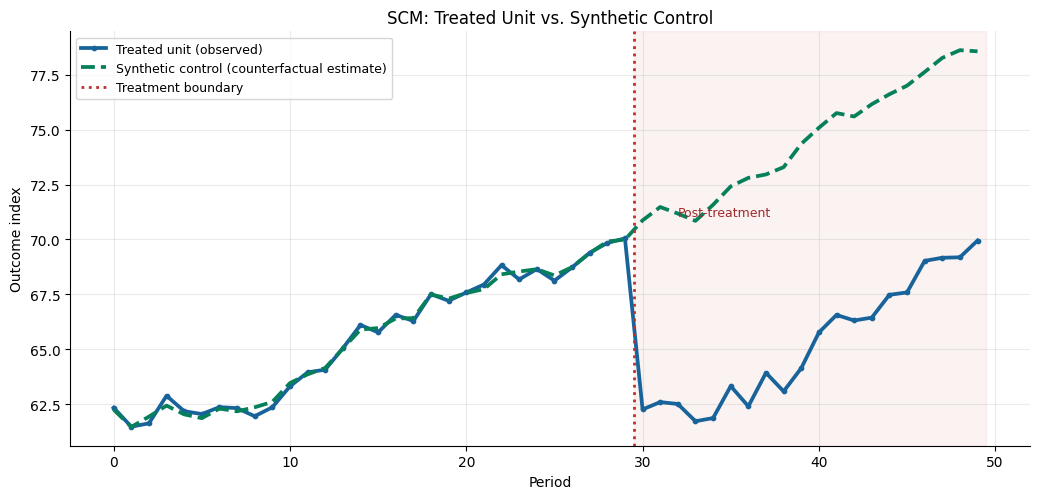

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 5.1))
ax.plot(periods, observed, color="#17639a", lw=2.7, marker="o", markersize=3.1, label="Treated unit (observed)")
ax.plot(periods, synthetic, color="#06805a", lw=2.7, ls="--", label="Synthetic control (counterfactual estimate)")
ax.axvline(T0 - 0.5, color="#c22d2d", linestyle=":", lw=2, label="Treatment boundary")
ax.axvspan(T0 - 0.5, T-0.5, color="#c22d2d", alpha=0.06)
ax.set(title="SCM: Treated Unit vs. Synthetic Control", xlabel="Period", ylabel="Outcome index")
ax.legend(loc="upper left", fontsize=9)
ax.annotate("Post-treatment", xy=(T0+2, np.max(observed)+1), fontsize=9, color="#a12a2a")
plt.tight_layout()
plt.show()


## 5. 그래프 ② 격차(Gap = Actual − Synthetic)

정책효과는 두 경로의 **직접적인 차이**로 읽습니다. 정책 전 격차가 작고, 시행 후 격차가 지속적으로 0보다 아래에 있다면 음(-)의 효과와 일관된 패턴입니다.


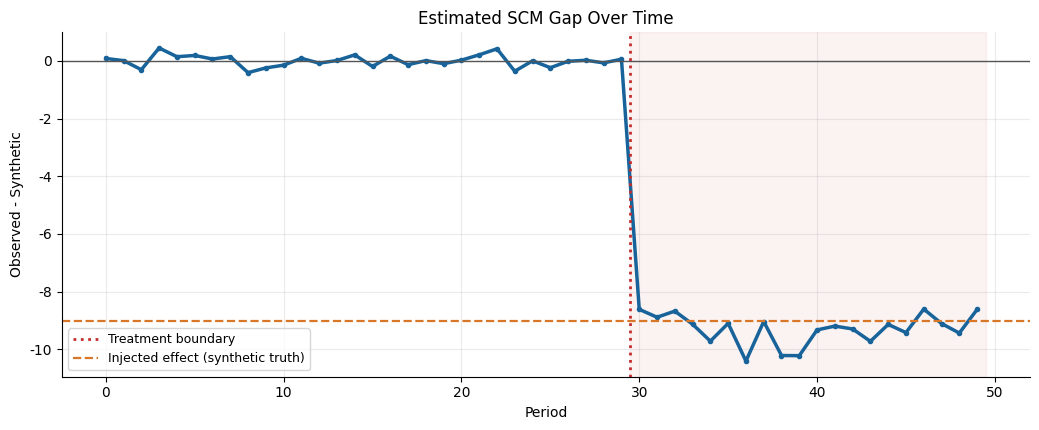

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
ax.plot(periods, gap, color="#17639a", lw=2.5, marker="o", markersize=3)
ax.axhline(0, color="#555555", lw=1)
ax.axvline(T0-0.5, color="#c22d2d", lw=2, ls=":", label="Treatment boundary")
ax.axhline(TAU_TRUE, color="#d97728", lw=1.6, ls="--", label="Injected effect (synthetic truth)")
ax.axvspan(T0-0.5, T-0.5, color="#c22d2d", alpha=0.06)
ax.set(title="Estimated SCM Gap Over Time", xlabel="Period", ylabel="Observed - Synthetic")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()


## 6. In-space placebo: 비교지역마다 자기만의 합성통제를 만든다

올바른 위약검정에서는 가짜 처리지역마다 **해당 지역을 도너에서 제외**하고 나머지 비처치 지역만으로 합성통제를 다시 학습합니다. 한 개의 초록색 선을 모든 지역에 공통으로 적용하지 않습니다.

비교의 공정성을 위해 사전 적합도(RMSPE)가 처리지역의 `5배`를 넘는 위약지역은 보조 그래프에서 제외할 수 있습니다. 이는 임의적 임계값이므로 해석 시 민감도를 확인해야 합니다.


In [6]:
placebo_rows = []
placebo_gaps = {}
for fake in unit_names:
    donor_pool = [c for c in unit_names if c != fake]
    w_fake, s_fake = fit_scm(panel[fake].to_numpy(), panel[donor_pool].to_numpy())
    g_fake = panel[fake].to_numpy() - s_fake
    p_pre = float(np.sqrt(np.mean(g_fake[:T0]**2)))
    p_post = float(np.sqrt(np.mean(g_fake[T0:]**2)))
    placebo_rows.append({"unit": fake, "pre_rmspe": p_pre, "post_rmspe": p_post,
                         "post_pre_ratio": (p_post/p_pre if p_pre > 1e-12 else np.nan),
                         "post_avg_gap": float(g_fake[T0:].mean())})
    placebo_gaps[fake] = g_fake
placebo = pd.DataFrame(placebo_rows).set_index("unit")
placebo_display = placebo.round(3)
display(placebo_display.sort_values("post_pre_ratio", ascending=False))


,pre_rmspe,post_rmspe,post_pre_ratio,post_avg_gap
unit,,,,
Donor_14,0.632,3.928,6.217,-3.377
Donor_11,0.837,4.318,5.159,4.125
Donor_15,0.285,1.309,4.596,1.219
Donor_07,0.751,2.751,3.662,-1.871
Donor_04,0.573,2.090,3.645,-1.794
Donor_10,0.387,1.323,3.424,-1.252
Donor_12,1.004,3.041,3.028,2.665
Donor_01,0.228,0.688,3.018,0.455
Donor_06,0.662,1.565,2.362,-1.536


## 7. 그래프 ③ 처리지역 Gap과 가짜 처리지역 Gap 비교

굵은 파란 선은 실제 처리지역의 **관측−자기 합성통제** 격차입니다. 가는 회색 선 하나하나는 다른 지역을 가짜로 처리한 **관측−자기 합성통제** 격차입니다.


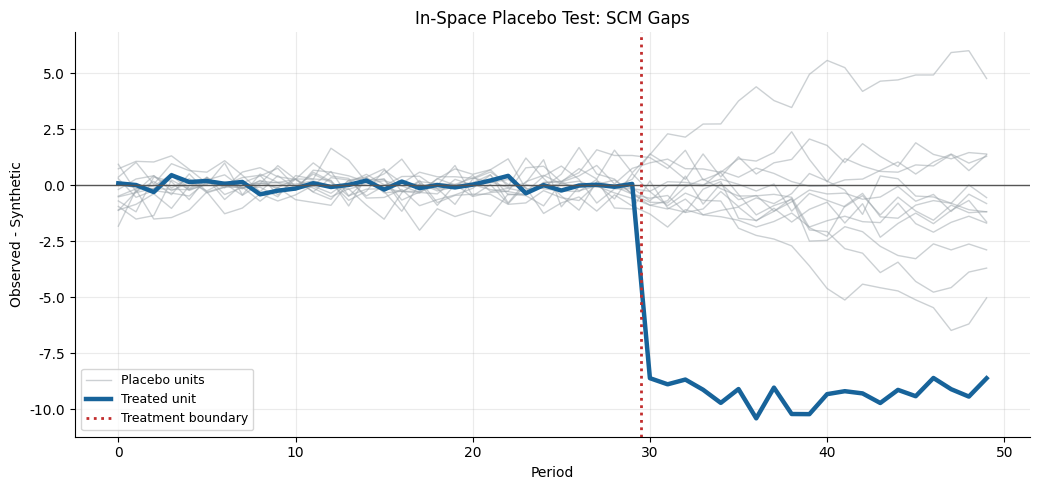

Eligible placebos after pre-fit filter: 13 / 16


In [7]:
pre_fit_multiplier = 5.0
eligible = placebo["pre_rmspe"] <= pre_fit_multiplier * pre_rmspe
eligible_units = list(placebo.index[eligible])
fig, ax = plt.subplots(figsize=(10.5, 5.0))
for j, fake in enumerate(eligible_units):
    ax.plot(periods, placebo_gaps[fake], color="#9aa3a9", alpha=0.50, lw=1.0,
            label="Placebo units" if j == 0 else None)
ax.plot(periods, gap, color="#17639a", lw=3.2, label="Treated unit")
ax.axhline(0, color="#555555", lw=1)
ax.axvline(T0-0.5, color="#c22d2d", lw=2, ls=":", label="Treatment boundary")
ax.set(title="In-Space Placebo Test: SCM Gaps", xlabel="Period", ylabel="Observed - Synthetic")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Eligible placebos after pre-fit filter: {len(eligible_units)} / {len(unit_names)}")


## 8. 그래프 ④ Post/Pre RMSPE 비율과 위약 순위

**Post/Pre RMSPE**는 정책 이후의 격차가 정책 이전 오차에 비해 얼마나 커졌는지 나타냅니다. 사전 적합이 나쁜 위약지역은 효과 비교에 부적합할 수 있습니다.

교육용 *순위 기반* 값을 계산합니다. 여기서는 사전 적합 기준을 충족한 위약지역만 포함하며, `1 + exceed`를 `1 + 포함 위약 수`로 나눕니다. 이는 관측연구에서 정확한 무작위화 검정 p값을 보장하지 않습니다.


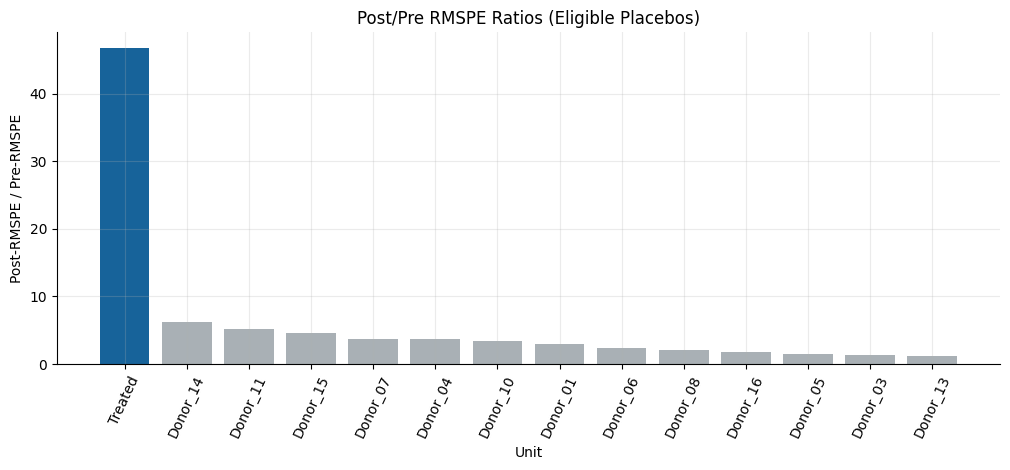

Treated ratio: 46.71
Rank-based placebo fraction: 0.071 (not a design-based exact p-value)


In [8]:
eligible_ratios = placebo.loc[eligible, "post_pre_ratio"].dropna()
rank_p = (1 + int((eligible_ratios >= ratio).sum())) / (1 + len(eligible_ratios))
ratio_table = pd.concat([
    pd.Series({"Treated": ratio}),
    eligible_ratios,
]).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10.2, 4.8))
colors = ["#17639a" if i == "Treated" else "#a9b0b5" for i in ratio_table.index]
ax.bar(ratio_table.index, ratio_table.values, color=colors)
ax.set(title="Post/Pre RMSPE Ratios (Eligible Placebos)", xlabel="Unit", ylabel="Post-RMSPE / Pre-RMSPE")
ax.tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()
print(f"Treated ratio: {ratio:.2f}")
print(f"Rank-based placebo fraction: {rank_p:.3f} (not a design-based exact p-value)")


## 9. 결과표와 해석 작성용 템플릿

숫자는 노트북 실행으로 계산됩니다. **실제 정책효과가 아니라 합성 데이터에서 주입한 효과를 SCM이 얼마나 회복하는지 보는 교육 실습**입니다.


In [9]:
summary = pd.DataFrame([
    {"Metric": "Known injected effect", "Value": TAU_TRUE},
    {"Metric": "Estimated mean post-treatment gap", "Value": avg_effect},
    {"Metric": "Absolute estimation error", "Value": abs(avg_effect - TAU_TRUE)},
    {"Metric": "Pre-treatment RMSPE", "Value": pre_rmspe},
    {"Metric": "Post-treatment RMSPE", "Value": post_rmspe},
    {"Metric": "Post/Pre RMSPE ratio", "Value": ratio},
    {"Metric": "Placebo rank fraction (eligible)", "Value": rank_p},
])
display(summary.round(3))
print("Interpretation: The post-treatment SCM gap should be compared with")
print("the known injected effect (-9) because this dataset is synthetic.")


,Metric,Value
0,Known injected effect,-9.000
1,Estimated mean post-treatment gap,-9.291
2,Absolute estimation error,0.291
3,Pre-treatment RMSPE,0.199
4,Post-treatment RMSPE,9.305
5,Post/Pre RMSPE ratio,46.710
6,Placebo rank fraction (eligible),0.071


Interpretation: The post-treatment SCM gap should be compared with
the known injected effect (-9) because this dataset is synthetic.


## 10. 강의용 결과 해석과 연구상 주의사항

**그래프 해설**

1. **Actual vs Synthetic**: 정책 이전 두 경로의 적합이 좋아야 정책 이후 합성 경로를 반사실 후보로 볼 수 있습니다.
2. **Gap**: 정책 이후 실제−합성 값이 음(-)이면 합성통제보다 실제 결과가 낮다는 의미입니다.
3. **Placebo**: 가짜 처치지역도 각각 합성통제를 다시 만들어 격차를 비교합니다. 실제 처리지역 격차가 특별히 크면 정책효과 가설을 지지할 수 있지만, 이것만으로 식별이 자동 보장되지는 않습니다.
4. **RMSPE ratio**: 가짜 지역의 사전 적합도가 나쁘면 보조 필터를 적용할 수 있으며, 필터에 따른 순위 변화도 보고해야 합니다.

**실제 논문에 적용할 때 추가할 검증**

- 처치 배정의 내생성, **동시 정책·사전 예상효과**, 도너지역에 대한 **간섭(spillover)** 여부.
- 도너 풀 선택, 가중치, 사전기간 길이, Leave-one-out 민감도, 구조적 단절 여부.
- 정책 효과의 크기와 불확실성을 **식별가정에 맞추어** 해석할 것.
- 연구 결과 표에는 데이터 출처·처치시점·전처리·도너 목록·가중치·RMSPE·검정 규칙을 명시할 것.

**실습 문제**: `TAU_TRUE`를 `0`, `-5`, `-12`로 바꾸거나 `T0`를 변경한 뒤, 정책 추정효과와 위약 순위가 어떻게 달라지는지 비교해 보세요.
